# DINOv2 Baseline Ablation Study Evaluation (Video-to-Video)

This notebook evaluates distance matrices generated by the ablation runs against the chosen **DINOv2 Baseline** on the DogReID-1553 closed-world video-to-video test set.

It computes and provides:
1. **mAP** (mean Average Precision) with 95% Bootstrap Confidence Intervals
2. **Rank-1, Rank-5, and Rank-10** Cumulative Matching Characteristic (CMC) with 95% Bootstrap Confidence Intervals
3. **Delta ($\Delta$) from Baseline** for Rank-1 and mAP to highlight relative gains/drops
4. **Categorized Breakdown Tables**:
   - **Backbone Adaptation Depth**: Frozen (0), 2, 4, 6 (Baseline), 8, 10, 12 blocks, and Full Fine-tuning
   - **Spatial & Multi-Layer Representation**: Pure `[CLS]` (Baseline), Patch Mean, Patch GeM, CLS+Mean, CLS+GeM, and Multi-Layer Fusion (`fuse4`)
   - **Feature Normalization & Neck**: BNNeck (Baseline) vs. No BNNeck (direct linear projection)
   - **Metric-Learning Objective**: Batch-Hard Triplet (Baseline), Soft Triplet, and Weighted Triplet
   - **Data Augmentation & Regularization**: RE + LS (Baseline), No RE, No LS, and AutoAugment
5. **Publication-Ready LaTeX Code Generator**: Pre-formatted tables directly pasteable into paper/appendix
6. **Visualizations**: Summary bar chart comparing all configurations against the baseline


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add root directory to sys.path
CURRENT_DIR = Path.cwd()
ROOT_DIR = CURRENT_DIR if (CURRENT_DIR / "evaluation").exists() else CURRENT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))
if str(ROOT_DIR / "evaluation") not in sys.path:
    sys.path.append(str(ROOT_DIR / "evaluation"))

from evaluation.evaluation_utils import bootstrap_from_csv

print("Loaded evaluation_utils successfully!")
print(f"Project root: {ROOT_DIR}")


Loaded evaluation_utils successfully!
Project root: /d/hpc/projects/FRI/mm12755/DogReID-1553/DogReID-1553


In [2]:
# =====================================================================
# Configuration: Ablation Registry & Discovery
# =====================================================================
ABLATIONS_DIR = ROOT_DIR / "evaluation" / "csvs_ablations"

ABLATION_METADATA = {
    # Baseline
    "baseline": {
        "category": "0. Baseline Reference",
        "display_name": "DINOv2 Baseline (Chosen)",
        "config_desc": "Unfreeze 6, [CLS], BNNeck, Batch-Hard, RE (0.5), LS (0.1), Cosine",
        "order": 0
    },
    # 1. Depth
    "unfreeze0": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Frozen Backbone (0 blocks)",
        "config_desc": "Only temporal pooling + BNNeck trained",
        "order": 10
    },
    "unfreeze2": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Unfreeze 2 blocks",
        "config_desc": "Blocks 10-11 unfrozen",
        "order": 11
    },
    "unfreeze4": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Unfreeze 4 blocks",
        "config_desc": "Blocks 8-11 unfrozen",
        "order": 12
    },
    "unfreeze6": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Unfreeze 6 blocks (Baseline)",
        "config_desc": "Blocks 6-11 unfrozen",
        "order": 13
    },
    "unfreeze8": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Unfreeze 8 blocks",
        "config_desc": "Blocks 4-11 unfrozen",
        "order": 14
    },
    "unfreeze10": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Unfreeze 10 blocks",
        "config_desc": "Blocks 2-11 unfrozen",
        "order": 15
    },
    "unfreeze12": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Unfreeze 12 blocks",
        "config_desc": "All 12 transformer blocks unfrozen",
        "order": 16
    },
    "full_finetune": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Full Fine-tune",
        "config_desc": "All blocks + patch embed + final norm unfrozen",
        "order": 17
    },
    # 2. Token / Layer Representation
    "cls": {
        "category": "2. Spatial & Multi-Layer Representation",
        "display_name": "Pure [CLS] Token (Baseline)",
        "config_desc": "Final layer [CLS] token representation",
        "order": 20
    },
    "patch_mean": {
        "category": "2. Spatial & Multi-Layer Representation",
        "display_name": "Patch Mean Pooling",
        "config_desc": "Mean across spatial patch tokens",
        "order": 21
    },
    "patch_gem": {
        "category": "2. Spatial & Multi-Layer Representation",
        "display_name": "Patch GeM Pooling",
        "config_desc": "Generalized mean pooling (p=3.0) on patch tokens",
        "order": 22
    },
    "cls_mean": {
        "category": "2. Spatial & Multi-Layer Representation",
        "display_name": "CLS + Patch Mean",
        "config_desc": "Concatenation of CLS token and patch mean",
        "order": 23
    },
    "cls_gem": {
        "category": "2. Spatial & Multi-Layer Representation",
        "display_name": "CLS + Patch GeM",
        "config_desc": "Concatenation of CLS token and patch GeM",
        "order": 24
    },
    "fuse4": {
        "category": "2. Spatial & Multi-Layer Representation",
        "display_name": "Multi-Layer Fusion (fuse4)",
        "config_desc": "Softmax-weighted fusion across blocks 8-11",
        "order": 25
    },
    # 3. Normalization & Neck
    "bnneck": {
        "category": "3. Feature Normalization & Neck",
        "display_name": "BNNeck (Baseline)",
        "config_desc": "Linear projection + BatchNorm1d neck",
        "order": 30
    },
    "no_bnneck": {
        "category": "3. Feature Normalization & Neck",
        "display_name": "No BNNeck",
        "config_desc": "Direct linear projection without BatchNorm neck",
        "order": 31
    },
    # 4. Metric Loss
    "batch_hard": {
        "category": "4. Metric-Learning Objective",
        "display_name": "Batch-Hard Triplet (Baseline)",
        "config_desc": "Hard Euclidean triplet loss (margin = 0.3)",
        "order": 40
    },
    "soft_triplet": {
        "category": "4. Metric-Learning Objective",
        "display_name": "Soft Triplet Loss",
        "config_desc": "Smooth soft-margin triplet loss without fixed margin",
        "order": 41
    },
    "weighted_triplet": {
        "category": "4. Metric-Learning Objective",
        "display_name": "Weighted Triplet Loss",
        "config_desc": "Distance-weighted batch triplet loss",
        "order": 42
    },
    # 5. Regularization & Augmentation
    "standard_aug": {
        "category": "5. Data Augmentation & Regularization",
        "display_name": "RE + LS (Baseline)",
        "config_desc": "Random Erasing (p=0.5) + Label Smoothing (0.1)",
        "order": 50
    },
    "no_re": {
        "category": "5. Data Augmentation & Regularization",
        "display_name": "No Random Erasing",
        "config_desc": "Random Erasing probability p = 0.0",
        "order": 51
    },
    "no_ls": {
        "category": "5. Data Augmentation & Regularization",
        "display_name": "No Label Smoothing",
        "config_desc": "Standard cross-entropy (epsilon = 0.0)",
        "order": 52
    },
    "autoaug": {
        "category": "5. Data Augmentation & Regularization",
        "display_name": "AutoAugment (SBS)",
        "config_desc": "ImageNet AutoAugment policy (p=0.1)",
        "order": 53
    },
    # 6. Backbone Architecture
    "clip_backbone": {
        "category": "6. Backbone Architecture",
        "display_name": "CLIP ViT-B/16 Backbone",
        "config_desc": "Same baseline recipe with OpenAI CLIP ViT-B/16 instead of DINOv2",
        "order": 60
    },
    # 7. Temporal Aggregation
    "temporal_mean": {
        "category": "7. Temporal Aggregation",
        "display_name": "Temporal Mean Pooling",
        "config_desc": "Simple average pooling across 8 frames instead of attention",
        "order": 70
    },
    "temporal_max": {
        "category": "7. Temporal Aggregation",
        "display_name": "Temporal Max Pooling",
        "config_desc": "Element-wise max pooling across 8 frames instead of attention",
        "order": 71
    }
}

discovered_ablations = {}
if ABLATIONS_DIR.exists():
    for p in sorted(ABLATIONS_DIR.iterdir()):
        if not p.is_dir():
            continue
        key = p.name.replace("_vid2vid", "").replace("_img2vid", "")
        csv_candidates = list(p.glob("*closed*.csv")) + list(p.glob("*.csv"))
        for c in csv_candidates:
            if c.stat().st_size > 1000:
                meta = ABLATION_METADATA.get(key, {
                    "category": "6. Other Ablations",
                    "display_name": key.replace("_", " ").title(),
                    "config_desc": p.name,
                    "order": 99
                })
                discovered_ablations[key] = {
                    "key": key,
                    "folder": p.name,
                    "csv_path": c,
                    **meta
                }
                break

print(f"Total ablation directories discovered with valid CSVs: {len(discovered_ablations)}")
print("-" * 80)
for k, v in discovered_ablations.items():
    cat = v['category']
    disp = v['display_name']
    rel_path = v['csv_path'].relative_to(ROOT_DIR)
    print(f"[{cat}] {disp:<30} -> {rel_path}")


Total ablation directories discovered with valid CSVs: 16
--------------------------------------------------------------------------------
[0. Baseline Reference] DINOv2 Baseline (Chosen)       -> evaluation/csvs_ablations/baseline_vid2vid/closed_dist_matrix.csv
[2. Spatial & Multi-Layer Representation] CLS + Patch GeM                -> evaluation/csvs_ablations/cls_gem_vid2vid/closed_dist_matrix.csv
[2. Spatial & Multi-Layer Representation] CLS + Patch Mean               -> evaluation/csvs_ablations/cls_mean_vid2vid/closed_dist_matrix.csv
[1. Backbone Adaptation Depth] Full Fine-tune                 -> evaluation/csvs_ablations/full_finetune_vid2vid/closed_dist_matrix.csv
[2. Spatial & Multi-Layer Representation] Multi-Layer Fusion (fuse4)     -> evaluation/csvs_ablations/fuse4_vid2vid/closed_dist_matrix.csv
[3. Feature Normalization & Neck] No BNNeck                      -> evaluation/csvs_ablations/no_bnneck_vid2vid/closed_dist_matrix.csv
[5. Data Augmentation & Regularization] No R

In [3]:
# =====================================================================
# Run Bootstrap Evaluation on Available CSVs
# =====================================================================
M_ITERATIONS = 100  # Number of bootstrap resamples for 95% Confidence Intervals
all_ablation_results = {}

for key, item in discovered_ablations.items():
    csv_file = item["csv_path"]
    disp_name = item["display_name"]
    print("=" * 70)
    print(f"Evaluating {disp_name} ({key}) from {csv_file.name} ...")
    print("=" * 70)
    try:
        res = bootstrap_from_csv(str(csv_file), m=M_ITERATIONS, mode="closed")
        all_ablation_results[key] = {
            "meta": item,
            "metrics": res
        }
    except Exception as e:
        print(f"[ERROR] Failed to evaluate {key}: {e}")

print(f"\n[DONE] Successfully evaluated {len(all_ablation_results)} ablations!")


Evaluating DINOv2 Baseline (Chosen) (baseline) from closed_dist_matrix.csv ...


-> Calculating full set metrics (closed)...
-> Bootstrapping 'closed' metrics (100 iterations)...


100%|██████████| 100/100 [00:01<00:00, 56.78it/s]


-> [CACHE SAVED] Saved bootstrap metrics to bootstrap_cache_closed_m100_seed42.pkl
Evaluating CLS + Patch GeM (cls_gem) from closed_dist_matrix.csv ...
-> Calculating full set metrics (closed)...
-> Bootstrapping 'closed' metrics (100 iterations)...


100%|██████████| 100/100 [00:01<00:00, 56.13it/s]


...

-> [CACHE SAVED] Saved bootstrap metrics to bootstrap_cache_closed_m100_seed42.pkl
Evaluating Unfreeze 8 blocks (unfreeze8) from closed_dist_matrix.csv ...
-> Calculating full set metrics (closed)...
-> Bootstrapping 'closed' metrics (100 iterations)...


100%|██████████| 100/100 [00:01<00:00, 56.34it/s]


-> [CACHE SAVED] Saved bootstrap metrics to bootstrap_cache_closed_m100_seed42.pkl
Evaluating Weighted Triplet Loss (weighted_triplet) from closed_dist_matrix.csv ...
-> Calculating full set metrics (closed)...
-> Bootstrapping 'closed' metrics (100 iterations)...


100%|██████████| 100/100 [00:01<00:00, 56.44it/s]

-> [CACHE SAVED] Saved bootstrap metrics to bootstrap_cache_closed_m100_seed42.pkl

[DONE] Successfully evaluated 16 ablations!


In [4]:
# =====================================================================
# Full Results Table (with Baseline comparison & deltas)
# =====================================================================
rows = []

# Baseline reference metrics for delta calculation
base_res = all_ablation_results.get("baseline", {}).get("metrics", {})
base_mAP = base_res.get("mAP_boot_mean", None)
base_cmc = base_res.get("cmc_boot_mean", None)
base_r1 = base_cmc[0] if base_cmc is not None and len(base_cmc) > 0 else None

for key, entry in all_ablation_results.items():
    meta = entry["meta"]
    res = entry["metrics"]
    full = res.get("full_set", {})
    
    # mAP
    m_mean = res.get("mAP_boot_mean", full.get("mAP", 0.0)) * 100
    m_ci = res.get("mAP_ci", (0.0, 0.0))
    m_low, m_high = m_ci[0] * 100, m_ci[1] * 100
    
    # CMC Rank-1, Rank-5, Rank-10
    cmc_boot = res.get("cmc_boot_mean", full.get("cmc", np.zeros(10)))
    cmc_l = res.get("cmc_ci_lower", cmc_boot)
    cmc_u = res.get("cmc_ci_upper", cmc_boot)
    
    r1 = cmc_boot[0] * 100
    r1_l, r1_u = cmc_l[0] * 100, cmc_u[0] * 100
    
    r5 = cmc_boot[4] * 100 if len(cmc_boot) >= 5 else 0.0
    r5_l, r5_u = cmc_l[4] * 100, cmc_u[4] * 100
    
    r10 = cmc_boot[9] * 100 if len(cmc_boot) >= 10 else 0.0
    r10_l, r10_u = cmc_l[9] * 100, cmc_u[9] * 100
    
    # Deltas
    delta_r1 = (r1 - base_r1 * 100) if base_r1 is not None else 0.0
    delta_map = (m_mean - base_mAP * 100) if base_mAP is not None else 0.0
    delta_str = f"{delta_r1:+.2f} / {delta_map:+.2f}" if key != "baseline" else "Reference"
    
    rows.append({
        "Key": key,
        "Order": meta.get("order", 99),
        "Category": meta.get("category", "Other"),
        "Variant": meta.get("display_name", key),
        "Description": meta.get("config_desc", ""),
        "Rank-1 (%) [95% CI]": f"{r1:.2f} [{r1_l:.2f}-{r1_u:.2f}]",
        "mAP (%) [95% CI]": f"{m_mean:.2f} [{m_low:.2f}-{m_high:.2f}]",
        "Rank-5 (%) [95% CI]": f"{r5:.2f} [{r5_l:.2f}-{r5_u:.2f}]",
        "Δ R-1 / Δ mAP": delta_str,
        "Rank-1_raw": r1,
        "mAP_raw": m_mean,
        "Rank-5_raw": r5
    })

df_all = pd.DataFrame(rows).sort_values("Order").reset_index(drop=True)

hdr_var = "Variant"
hdr_r1 = "Rank-1 [95% CI]"
hdr_map = "mAP [95% CI]"
hdr_delta = "Δ (R-1/mAP)"
hdr_cat = "Category"

print("=" * 120)
print(f"{hdr_var:<30} | {hdr_r1:<24} | {hdr_map:<24} | {hdr_delta:<14} | {hdr_cat}")
print("=" * 120)
for _, r in df_all.iterrows():
    v = r["Variant"]
    r1_s = r["Rank-1 (%) [95% CI]"]
    map_s = r["mAP (%) [95% CI]"]
    d_s = r["Δ R-1 / Δ mAP"]
    c_s = r["Category"]
    print(f"{v:<30} | {r1_s:<24} | {map_s:<24} | {d_s:<14} | {c_s}")
print("-" * 120)

display_cols = ["Category", "Variant", "Rank-1 (%) [95% CI]", "mAP (%) [95% CI]", "Rank-5 (%) [95% CI]", "Δ R-1 / Δ mAP", "Description"]
df_all[display_cols]


Variant                        | Rank-1 [95% CI]          | mAP [95% CI]             | Δ (R-1/mAP)    | Category
DINOv2 Baseline (Chosen)       | 61.28 [58.46-64.19]      | 57.63 [55.57-59.94]      | Reference      | 0. Baseline Reference
Frozen Backbone (0 blocks)     | 43.59 [40.69-46.27]      | 41.74 [39.55-43.94]      | -17.69 / -15.89 | 1. Backbone Adaptation Depth
Unfreeze 2 blocks              | 61.86 [59.01-64.56]      | 58.04 [56.02-60.44]      | +0.57 / +0.41  | 1. Backbone Adaptation Depth
Unfreeze 4 blocks              | 61.83 [59.13-64.78]      | 58.11 [56.11-60.40]      | +0.55 / +0.48  | 1. Backbone Adaptation Depth
Unfreeze 8 blocks              | 61.30 [58.40-64.27]      | 58.22 [56.01-60.62]      | +0.01 / +0.59  | 1. Backbone Adaptation Depth
Unfreeze 10 blocks             | 61.61 [59.06-64.69]      | 57.46 [55.55-60.01]      | +0.33 / -0.17  | 1. Backbone Adaptation Depth
Full Fine-tune                 | 60.52 [57.85-63.26]      | 56.61 [54.40-59.19]      | -0.76 / 

,Category,Variant,Rank-1 (%) [95% CI],mAP (%) [95% CI],Rank-5 (%) [95% CI],Δ R-1 / Δ mAP,Description
0,0. Baseline Reference,DINOv2 Baseline (Chosen),61.28 [58.46-64.19],57.63 [55.57-59.94],79.56 [77.21-81.74],Reference,"Unfreeze 6, [CLS], BNNeck, Batch-Hard, RE (0.5..."
1,1. Backbone Adaptation Depth,Frozen Backbone (0 blocks),43.59 [40.69-46.27],41.74 [39.55-43.94],65.97 [62.96-68.84],-17.69 / -15.89,Only temporal pooling + BNNeck trained
2,1. Backbone Adaptation Depth,Unfreeze 2 blocks,61.86 [59.01-64.56],58.04 [56.02-60.44],79.62 [76.94-81.97],+0.57 / +0.41,Blocks 10-11 unfrozen
3,1. Backbone Adaptation Depth,Unfreeze 4 blocks,61.83 [59.13-64.78],58.11 [56.11-60.40],79.20 [76.71-81.63],+0.55 / +0.48,Blocks 8-11 unfrozen
4,1. Backbone Adaptation Depth,Unfreeze 8 blocks,61.30 [58.40-64.27],58.22 [56.01-60.62],79.50 [76.97-81.89],+0.01 / +0.59,Blocks 4-11 unfrozen
5,1. Backbone Adaptation Depth,Unfreeze 10 blocks,61.61 [59.06-64.69],57.46 [55.55-60.01],78.93 [76.78-81.29],+0.33 / -0.17,Blocks 2-11 unfrozen
6,1. Backbone Adaptation Depth,Full Fine-tune,60.52 [57.85-63.26],56.61 [54.40-59.19],78.99 [76.72-81.57],-0.76 / -1.02,All blocks + patch embed + final norm unfrozen
7,2. Spatial & Multi-Layer Representation,Patch Mean Pooling,58.59 [55.49-61.33],55.51 [53.47-57.93],77.24 [74.84-79.62],-2.70 / -2.12,Mean across spatial patch tokens
8,2. Spatial & Multi-Layer Representation,Patch GeM Pooling,57.71 [54.83-60.59],54.08 [51.91-56.53],75.73 [73.37-78.34],-3.58 / -3.55,Generalized mean pooling (p=3.0) on patch tokens
9,2. Spatial & Multi-Layer Representation,CLS + Patch Mean,61.66 [59.22-64.22],58.11 [55.97-60.42],79.59 [77.38-81.72],+0.38 / +0.48,Concatenation of CLS token and patch mean


## Backbone Adaptation Depth Scaling (Rank-1 & mAP with 95% Confidence Intervals)

This plot visualizes how performance scales as transformer blocks are progressively unfrozen,
from completely frozen (0 blocks) up to full backbone fine-tuning, including 95% bootstrap confidence intervals.


-> Saved figure to /d/hpc/projects/FRI/mm12755/DogReID-1553/DogReID-1553/evaluation/figures/unfreezing_stages_scaling.png


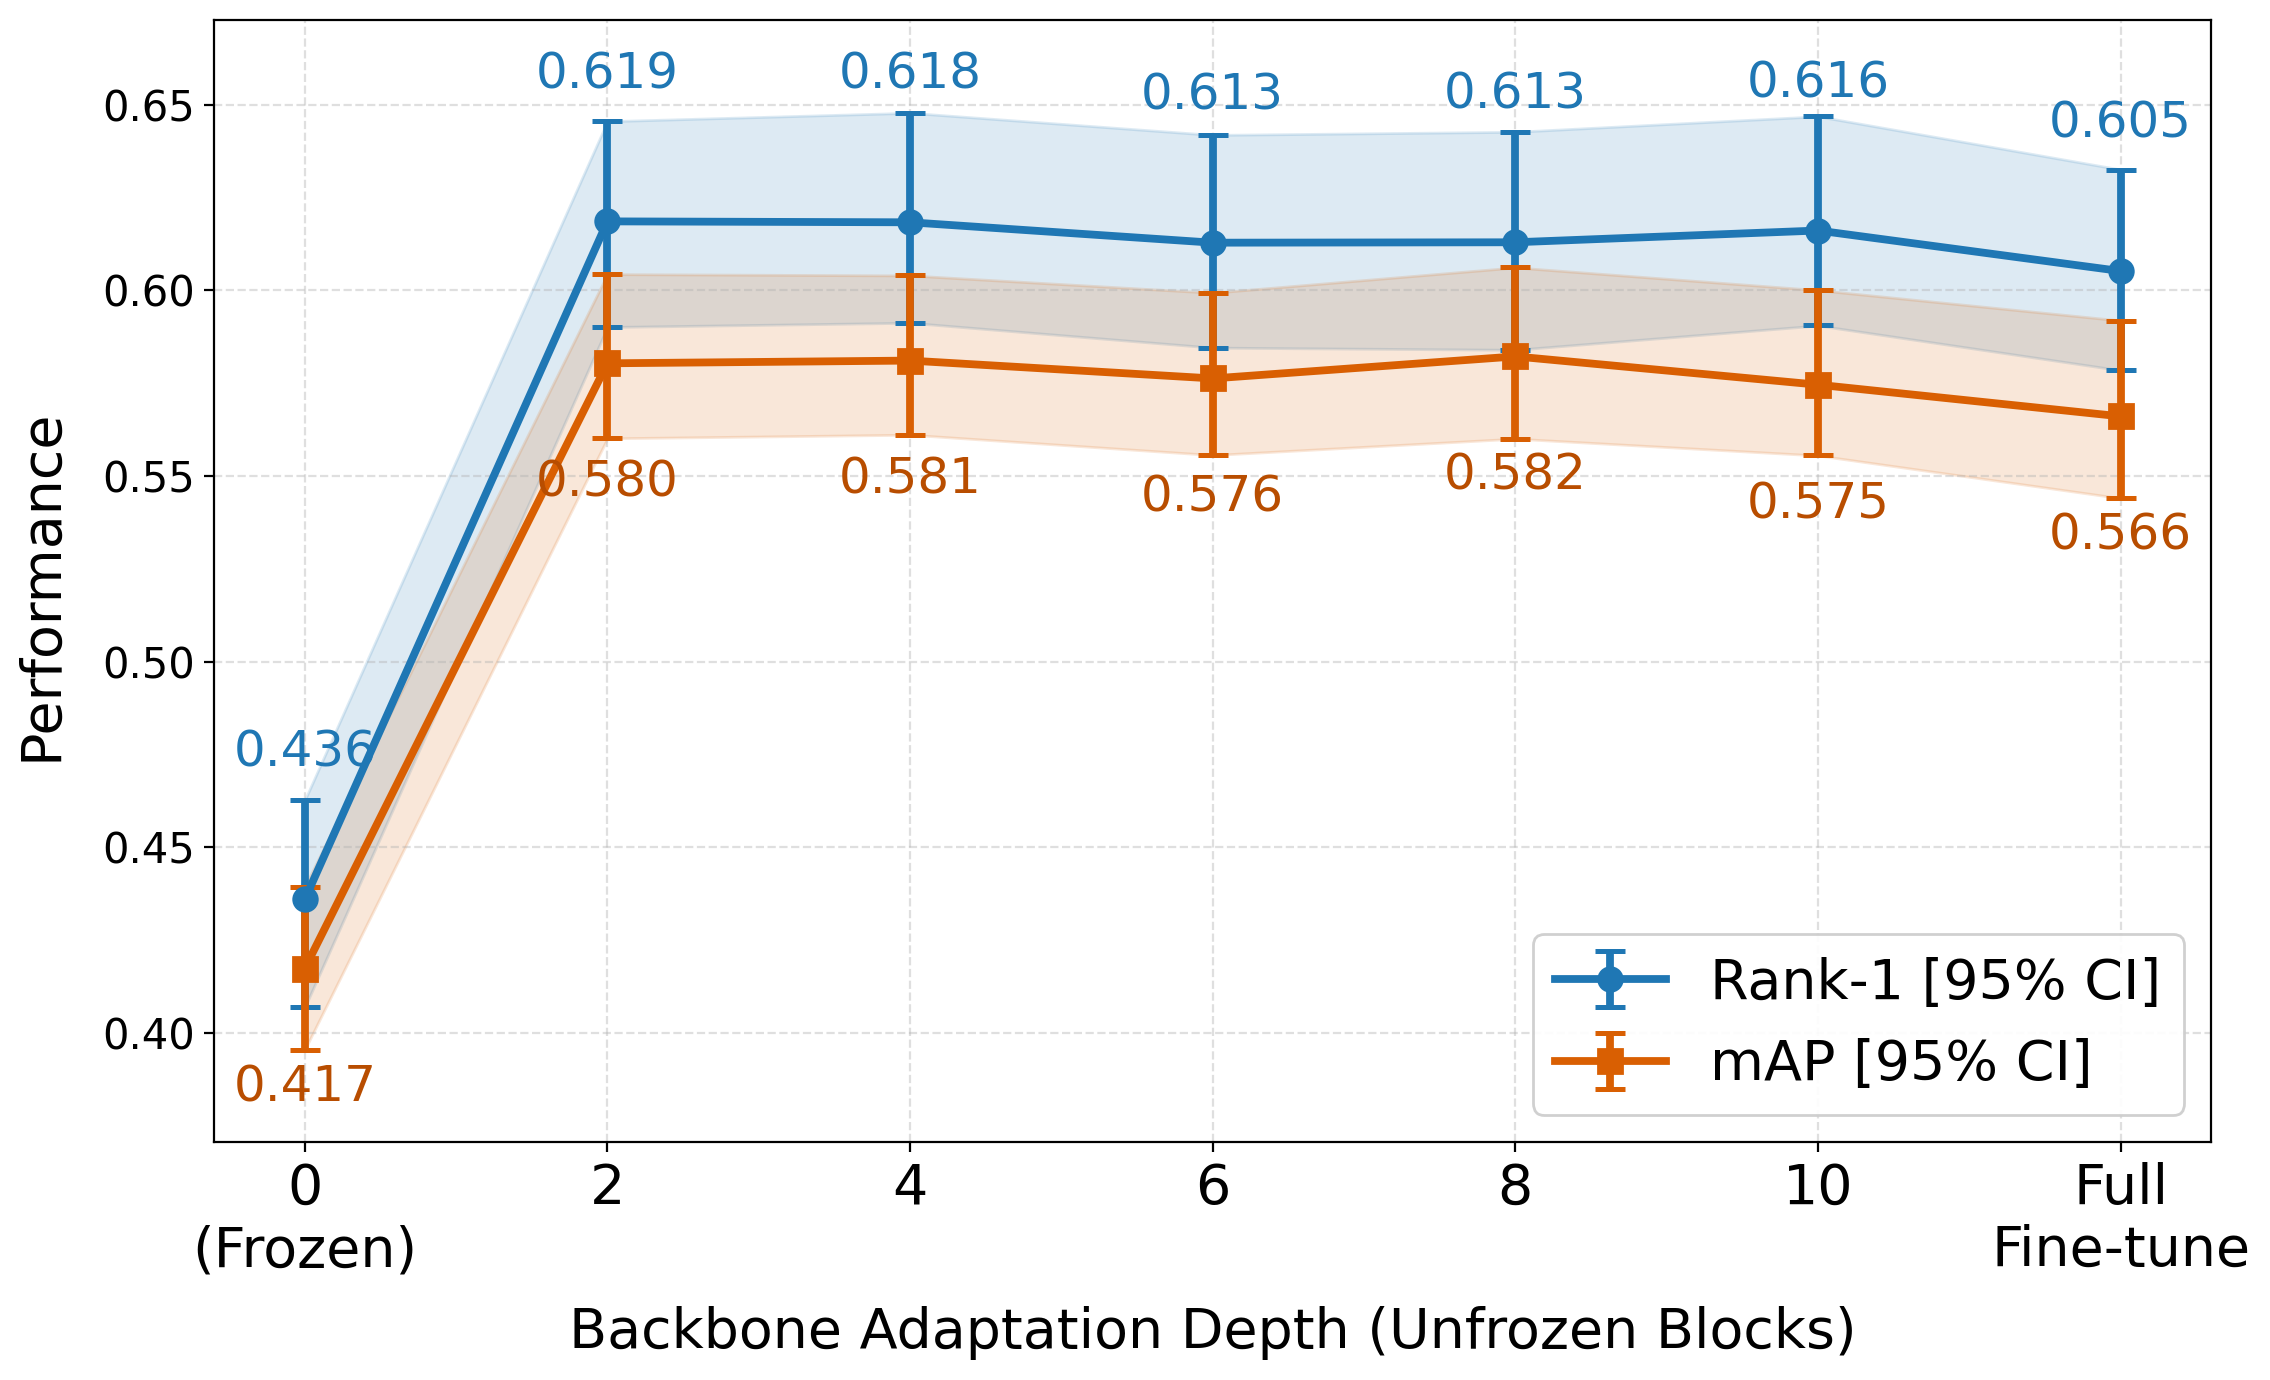

In [5]:
# =====================================================================
# Plot: Performance vs. Backbone Adaptation Depth (with 95% Bootstrap CIs)
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Ordered list of candidate depth stages
depth_stage_defs = [
    {"keys": ["unfreeze0"], "label": "0\n(Frozen)", "short": "0"},
    {"keys": ["unfreeze2"], "label": "2", "short": "2"},
    {"keys": ["unfreeze4"], "label": "4", "short": "4"},
    {"keys": ["baseline", "unfreeze6"], "label": "6", "short": "6", "is_base": True},
    {"keys": ["unfreeze8"], "label": "8", "short": "8"},
    {"keys": ["unfreeze10"], "label": "10", "short": "10"},
    {"keys": ["unfreeze12"], "label": "12", "short": "12"},
    {"keys": ["full_finetune"], "label": "Full\nFine-tune", "short": "Full FT"},
]

plot_stages = []
for stage in depth_stage_defs:
    for k in stage["keys"]:
        if k in all_ablation_results:
            res = all_ablation_results[k]["metrics"]
            full = res.get("full_set", {})
            
            cmc_boot = res.get("cmc_boot_mean", full.get("cmc", np.zeros(10)))
            cmc_l = res.get("cmc_ci_lower", cmc_boot)
            cmc_u = res.get("cmc_ci_upper", cmc_boot)
            r1 = cmc_boot[0]
            r1_l, r1_u = cmc_l[0], cmc_u[0]
            
            m_mean = res.get("mAP_boot_mean", full.get("mAP", 0.0))
            m_ci = res.get("mAP_ci", (0.0, 0.0))
            m_l, m_u = m_ci[0], m_ci[1]
            
            plot_stages.append({
                "key": k,
                "label": stage["label"],
                "short": stage["short"],
                "is_base": stage.get("is_base", False),
                "r1": r1,
                "r1_l": r1_l,
                "r1_u": r1_u,
                "map": m_mean,
                "map_l": m_l,
                "map_u": m_u,
            })
            break

if len(plot_stages) >= 2:
    fig, ax = plt.subplots(figsize=(11.5, 7.0), dpi=200)
    x_indices = np.arange(len(plot_stages))
    labels = [s["label"] for s in plot_stages]
    
    r1_vals = np.array([s["r1"] for s in plot_stages])
    r1_lows = np.array([s["r1_l"] for s in plot_stages])
    r1_highs = np.array([s["r1_u"] for s in plot_stages])
    
    map_vals = np.array([s["map"] for s in plot_stages])
    map_lows = np.array([s["map_l"] for s in plot_stages])
    map_highs = np.array([s["map_u"] for s in plot_stages])
    
    # Shaded 95% Confidence Interval bands
    ax.fill_between(x_indices, r1_lows, r1_highs, color="#1f77b4", alpha=0.15, label="_nolegend_")
    ax.fill_between(x_indices, map_lows, map_highs, color="#d95f02", alpha=0.15, label="_nolegend_")
    
    # Curves with error bars
    ax.errorbar(x_indices, r1_vals, yerr=[r1_vals - r1_lows, r1_highs - r1_vals],
                fmt="-o", color="#1f77b4", label="Rank-1 [95% CI]",
                linewidth=2.8, markersize=8.5, capsize=5.5, capthick=1.8)
    
    ax.errorbar(x_indices, map_vals, yerr=[map_vals - map_lows, map_highs - map_vals],
                fmt="-s", color="#d95f02", label="mAP [95% CI]",
                linewidth=2.8, markersize=8.5, capsize=5.5, capthick=1.8)
    
    # Annotate points with values
    for i, s in enumerate(plot_stages):
        ax.annotate(f"{s['r1']:.3f}", (i, s["r1"]), textcoords="offset points", xytext=(0, 48),
                    ha="center", fontsize=18, color="#1f77b4")
        ax.annotate(f"{s['map']:.3f}", (i, s["map"]), textcoords="offset points", xytext=(0, -48),
                    ha="center", fontsize=18, color="#b84d00")
    
    
    ax.set_xticks(x_indices)
    ax.set_xticklabels(labels, fontsize=20)
    ax.tick_params(axis="y", labelsize=15)
    ax.set_xlabel("Backbone Adaptation Depth (Unfrozen Blocks)", fontsize=20, labelpad=10)
    ax.set_ylabel("Performance ", fontsize=20, labelpad=10)
    ax.grid(True, linestyle="--", alpha=0.4)
    
    # Dynamic y-limit with breathing room
    y_min = max(0.0, min(map_lows) - 0.025)
    y_max = min(1.0, max(r1_highs) + 0.025)
    ax.set_ylim(y_min, y_max)
    
    ax.legend(loc="lower right", framealpha=0.92, fontsize=20)
    plt.tight_layout()
    
    # Save publication figure
    fig_dir = ROOT_DIR / "evaluation" / "figures"
    fig_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(fig_dir / "unfreezing_stages_scaling.png", dpi=300, bbox_inches="tight")
    plt.savefig(fig_dir / "unfreezing_stages_scaling.pdf", bbox_inches="tight")
    print("-> Saved figure to " + str(fig_dir / "unfreezing_stages_scaling.png"))
    plt.show()
else:
    print("[INFO] Insufficient depth stages discovered yet to render curve plot.")


## Diagnostic Evaluations (Subject Masking & Number of Frames)

Evaluation of the DINOv2 baseline under:
1. **Subject Masking & Crop Quality**: V2V background-only masking, and I2V queries with YOLO crop, GT crop, YOLO-masked, and GT-masked.
2. **Number of Frames**: Inference across 4, 8 (baseline), 16, and 32 frames with dynamic temporal attention pooling.

In [6]:
# =====================================================================
# Diagnostic Evaluations: Masking & Number of Frames Tables
# =====================================================================
DIAG_DIR = ROOT_DIR / "evaluation" / "csvs_diagnostics"
CLOSED_DIR = ROOT_DIR / "evaluation" / "csvs_closed_results"

def get_row(name, path, fallback_path=None, ref_r1=None, ref_map=None):
    p = path if path.exists() and path.stat().st_size > 0 else (fallback_path if fallback_path and fallback_path.exists() else None)
    if not p:
        return {"Setting": name, "Rank-1 (%) [95% CI]": "Pending...", "mAP (%) [95% CI]": "Pending...", "Δ (R-1 / mAP)": "-"}
    res = bootstrap_from_csv(str(p), m=100, mode="closed")
    m_mean = res.get("mAP_boot_mean", 0.0) * 100
    m_ci = res.get("mAP_ci", (0.0, 0.0))
    cmc = res.get("cmc_boot_mean", [0.0])[0] * 100
    cmc_ci = (res.get("cmc_ci_lower", [0.0])[0] * 100, res.get("cmc_ci_upper", [0.0])[0] * 100)
    delta = "Reference" if ref_r1 is None else f"{(cmc - ref_r1):+.2f} / {(m_mean - ref_map):+.2f}"
    return {
        "Setting": name,
        "Rank-1 (%) [95% CI]": f"{cmc:.2f} [{cmc_ci[0]:.2f}-{cmc_ci[1]:.2f}]",
        "mAP (%) [95% CI]": f"{m_mean:.2f} [{m_ci[0]*100:.2f}-{m_ci[1]*100:.2f}]",
        "Δ (R-1 / mAP)": delta,
        "_r1": cmc, "_map": m_mean
    }

# 1. Subject Masking & Crop Quality
base_v2v = get_row("V2V Standard (Unmasked)", CLOSED_DIR / "baseline_vid2vid" / "closed_dist_matrix.csv", ROOT_DIR / "evaluation/csvs_ablations/baseline/closed_dist_matrix.csv")
v2v_r1, v2v_map = base_v2v.get("_r1"), base_v2v.get("_map")

base_i2v = get_row("I2V Standard (YOLO Crop, Unmasked)", DIAG_DIR / "baseline_img2vid_unmasked_yolo" / "closed_dist_matrix.csv", CLOSED_DIR / "baseline_img2vid" / "closed_dist_matrix.csv")
i2v_r1, i2v_map = base_i2v.get("_r1"), base_i2v.get("_map")

masking_rows = [
    base_v2v,
    get_row("V2V YOLO-Masked (Background-Only)", DIAG_DIR / "baseline_vid2vid_masked" / "closed_dist_matrix.csv", ref_r1=v2v_r1, ref_map=v2v_map),
    base_i2v,
    get_row("I2V GT Crop (Unmasked)", DIAG_DIR / "baseline_img2vid_unmasked_gt" / "closed_dist_matrix.csv", DIAG_DIR / "baseline_img2vid_gt_query" / "closed_dist_matrix.csv", ref_r1=i2v_r1, ref_map=i2v_map),
    get_row("I2V YOLO-Masked Query", DIAG_DIR / "baseline_img2vid_masked_yolo" / "closed_dist_matrix.csv", ref_r1=i2v_r1, ref_map=i2v_map),
    get_row("I2V GT-Masked Query", DIAG_DIR / "baseline_img2vid_masked_gt" / "closed_dist_matrix.csv", ref_r1=i2v_r1, ref_map=i2v_map),
]
df_masking = pd.DataFrame(masking_rows)[["Setting", "Rank-1 (%) [95% CI]", "mAP (%) [95% CI]", "Δ (R-1 / mAP)"]]

# 2. Number of Frames (Temporal Scaling)
f8_r1, f8_map = v2v_r1, v2v_map
frame_rows = [
    get_row("4 Frames", DIAG_DIR / "baseline_vid2vid_len4" / "closed_dist_matrix.csv", ref_r1=f8_r1, ref_map=f8_map),
    {"Setting": "8 Frames (Baseline)", "Rank-1 (%) [95% CI]": base_v2v["Rank-1 (%) [95% CI]"], "mAP (%) [95% CI]": base_v2v["mAP (%) [95% CI]"], "Δ (R-1 / mAP)": "Reference"},
    get_row("16 Frames", DIAG_DIR / "baseline_vid2vid_len16" / "closed_dist_matrix.csv", ref_r1=f8_r1, ref_map=f8_map),
    get_row("32 Frames", DIAG_DIR / "baseline_vid2vid_len32" / "closed_dist_matrix.csv", ref_r1=f8_r1, ref_map=f8_map),
]
df_frames = pd.DataFrame(frame_rows)[["Setting", "Rank-1 (%) [95% CI]", "mAP (%) [95% CI]", "Δ (R-1 / mAP)"]]

print("=== Subject Masking & Crop Quality Diagnostic ===")
display(df_masking)

print("\n=== Number of Frames Inference Diagnostic ===")
display(df_frames)

-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded pr

,Setting,Rank-1 (%) [95% CI],mAP (%) [95% CI],Δ (R-1 / mAP)
0,V2V Standard (Unmasked),61.28 [58.46-64.19],57.63 [55.57-59.94],Reference
1,V2V YOLO-Masked (Background-Only),17.14 [14.85-19.05],16.28 [14.92-17.83],-44.14 / -41.34
2,"I2V Standard (YOLO Crop, Unmasked)",51.50 [48.83-54.57],49.98 [47.94-52.21],Reference
3,I2V GT Crop (Unmasked),53.93 [51.35-57.28],52.76 [50.89-55.35],+2.43 / +2.78
4,I2V YOLO-Masked Query,6.54 [5.28-7.82],6.53 [5.77-7.42],-44.95 / -43.45
5,I2V GT-Masked Query,0.18 [0.00-0.42],1.05 [0.85-1.24],-51.31 / -48.93



=== Number of Frames Inference Diagnostic ===


,Setting,Rank-1 (%) [95% CI],mAP (%) [95% CI],Δ (R-1 / mAP)
0,4 Frames,59.44 [56.87-62.27],55.17 [53.31-57.55],-1.85 / -2.46
1,8 Frames (Baseline),61.28 [58.46-64.19],57.63 [55.57-59.94],Reference
2,16 Frames,62.32 [59.74-65.68],58.64 [56.50-61.29],+1.04 / +1.01
3,32 Frames,62.72 [60.01-65.66],59.09 [56.83-61.54],+1.44 / +1.46
